# 01 — Data profiling of the raw Olist CSVs

**Project question:** why do almost all Olist customers buy only once, and what should Olist fix first?

**Purpose of this notebook:** *measure* the nine raw CSVs in `data/raw/` and find every data-quality issue
**before** any cleaning rule is decided. Nothing here changes data: no rows are dropped, nothing is written to
`data/processed/`. The only file written is `outputs/phase2_profile_summary.csv` (the Key numbers table at the end).

**How to read it:** every section starts with the question in plain English, then the code, then a
**Finding** cell. Findings quote only numbers printed by the cells above them.

| # | Section |
|---|---------|
| 0 | Load + table overview (rows, dtypes, nulls, duplicates, key uniqueness) |
| 1 | Customers: `customer_id` vs `customer_unique_id`, one-time buyers |
| 2 | Order status |
| 3 | Orders per month and the analysis window |
| 4 | Date problems |
| 5 | Reviews: duplicates and "one review per order" |
| 6 | Payments vs item totals |
| 7 | Items per order |
| 8 | Geolocation |
| 9 | Products and category translation |
| 10 | Price and freight distributions |
| 11 | Referential integrity |
| 12 | Key numbers (saved to CSV) |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Proof that the notebook runs on the project's .venv (Python 3.11, pandas 3.x).
print("Python executable:", sys.executable)
print("pandas version:   ", pd.__version__)
# Stop early if Jupyter picked the wrong Python (it happened once: see the kernel note in docs).
assert ".venv" in sys.prefix, "Not running on the project .venv - select the 'Python 3.11 (olist .venv)' kernel."

# nbconvert/Jupyter run the notebook with the notebooks/ folder as working directory.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = REPO_ROOT / "data" / "raw"
OUT = REPO_ROOT / "outputs"
print("Raw data folder:  ", RAW)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

Python executable: D:\Projects\olist-retention-analysis\.venv\Scripts\python.exe
pandas version:    3.1.1
Raw data folder:   D:\Projects\olist-retention-analysis\data\raw


## 0. Load the nine CSVs and get an overview

**Question:** how big is each table, what type is each column, where are the blanks, are there fully duplicated
rows, and is each table's intended key really unique?

Loading choices:
- Timestamp columns are parsed as datetimes (`parse_dates`) so we can compare and subtract them.
- Zip-code prefixes are read as **text** (`dtype=str`). Read as numbers, `"01037"` would become `1037` and stop matching.
- The translation file starts with an invisible byte-order mark (BOM); `encoding="utf-8-sig"` strips it so the first
  column is called `product_category_name`, not `\ufeffproduct_category_name`.

In [2]:
ORDER_DATES = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(RAW / "olist_orders_dataset.csv", parse_dates=ORDER_DATES)
customers = pd.read_csv(RAW / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
items = pd.read_csv(RAW / "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(
    RAW / "olist_order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)
products = pd.read_csv(RAW / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
geo = pd.read_csv(RAW / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
translation = pd.read_csv(RAW / "product_category_name_translation.csv", encoding="utf-8-sig")

# One dictionary so we can loop over every table.
tables = {
    "orders": orders,
    "customers": customers,
    "order_items": items,
    "order_payments": payments,
    "order_reviews": reviews,
    "products": products,
    "sellers": sellers,
    "geolocation": geo,
    "category_translation": translation,
}

# Overview: one row per table.
overview = pd.DataFrame(
    [
        {
            "table": name,
            "rows": len(df),
            "columns": df.shape[1],
            "fully_duplicated_rows": int(df.duplicated().sum()),  # rows identical to an earlier row in every column
            "total_null_cells": int(df.isna().sum().sum()),
        }
        for name, df in tables.items()
    ]
)
overview

,table,rows,columns,fully_duplicated_rows,total_null_cells
0,orders,99441,8,0,4908
1,customers,99441,5,0,0
2,order_items,112650,7,0,0
3,order_payments,103886,5,0,0
4,order_reviews,99224,7,0,145903
5,products,32951,9,0,2448
6,sellers,3095,4,0,0
7,geolocation,1000163,5,261831,0
8,category_translation,71,2,0,0


### 0b. Column profile: dtype, null count and null % for every column

`profile_table` builds one small table per CSV. `df.isna().mean()` is the share of blanks in each column
(True counts as 1, False as 0, so the mean is the fraction that is blank).

In [3]:
def profile_table(df: pd.DataFrame) -> pd.DataFrame:
    """dtype, null count and null % for each column of df."""
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "null_count": df.isna().sum(),
            "null_pct": (df.isna().mean() * 100).round(2),
        }
    )


for name, df in tables.items():
    print(f"\n=== {name}  ({len(df):,} rows) ===")
    print(profile_table(df).to_string())


=== orders  (99,441 rows) ===
                                        dtype  null_count  null_pct
order_id                                  str           0      0.00
customer_id                               str           0      0.00
order_status                              str           0      0.00
order_purchase_timestamp       datetime64[us]           0      0.00
order_approved_at              datetime64[us]         160      0.16
order_delivered_carrier_date   datetime64[us]        1783      1.79
order_delivered_customer_date  datetime64[us]        2965      2.98
order_estimated_delivery_date  datetime64[us]           0      0.00

=== customers  (99,441 rows) ===
                         dtype  null_count  null_pct
customer_id                str           0       0.0
customer_unique_id         str           0       0.0
customer_zip_code_prefix   str           0       0.0
customer_city              str           0       0.0
customer_state             str           0       0.0

=== 

                               dtype  null_count  null_pct
geolocation_zip_code_prefix      str           0       0.0
geolocation_lat              float64           0       0.0
geolocation_lng              float64           0       0.0
geolocation_city                 str           0       0.0
geolocation_state                str           0       0.0

=== category_translation  (71 rows) ===
                              dtype  null_count  null_pct
product_category_name           str           0       0.0
product_category_name_english   str           0       0.0


### 0c. Is each table's intended key unique?

A key is unique when no value (or combination of values) appears twice. `duplicated(subset=cols)` marks every
repeat after the first, so its sum is the number of "extra" rows sharing a key with an earlier row.

In [4]:
KEYS = [
    ("orders", ["order_id"]),
    ("customers", ["customer_id"]),
    ("order_items", ["order_id", "order_item_id"]),
    ("order_payments", ["order_id", "payment_sequential"]),
    ("order_reviews", ["review_id"]),
    ("order_reviews", ["order_id"]),
    ("products", ["product_id"]),
    ("sellers", ["seller_id"]),
    ("geolocation", ["geolocation_zip_code_prefix"]),
    ("category_translation", ["product_category_name"]),
]


def key_check(df: pd.DataFrame, cols: list[str]) -> dict:
    """How many distinct key values, and how many rows repeat an earlier key."""
    extra_rows = int(df.duplicated(subset=cols).sum())
    return {
        "rows": len(df),
        "distinct_key_values": len(df.drop_duplicates(subset=cols)),
        "rows_repeating_a_key": extra_rows,
        "key_is_unique": extra_rows == 0,
    }


key_results = pd.DataFrame(
    [{"table": t, "key": " + ".join(cols), **key_check(tables[t], cols)} for t, cols in KEYS]
)
key_results

,table,key,rows,distinct_key_values,rows_repeating_a_key,key_is_unique
0,orders,order_id,99441,99441,0,True
1,customers,customer_id,99441,99441,0,True
2,order_items,order_id + order_item_id,112650,112650,0,True
3,order_payments,order_id + payment_sequential,103886,103886,0,True
4,order_reviews,review_id,99224,98410,814,False
5,order_reviews,order_id,99224,98673,551,False
6,products,product_id,32951,32951,0,True
7,sellers,seller_id,3095,3095,0,True
8,geolocation,geolocation_zip_code_prefix,1000163,19015,981148,False
9,category_translation,product_category_name,71,71,0,True


**Finding (0 overview)**

- Row counts: orders 99,441; customers 99,441; order_items 112,650; order_payments 103,886; order_reviews 99,224; products 32,951; sellers 3,095; geolocation 1,000,163; category_translation 71.
- Fully duplicated rows exist only in **geolocation: 261,831**. Every other table has 0.
- Nulls: orders has 160 missing `order_approved_at`, 1,783 missing `order_delivered_carrier_date` and 2,965 missing `order_delivered_customer_date` (these are mostly orders that never shipped; see section 4). Reviews: `review_comment_title` is 88.34% blank and `review_comment_message` 58.70% blank (optional free text, not an error). Products: 610 rows (1.85%) missing category, name length, description length and photo count; 2 rows missing weight and dimensions.
- Keys: orders, customers, order_items (`order_id + order_item_id`), order_payments (`order_id + payment_sequential`), products, sellers and category_translation are all **unique**.
- **Not unique:** `order_reviews.review_id` (814 rows repeat an earlier review_id), `order_reviews.order_id` (551 rows repeat an earlier order_id), and `geolocation_zip_code_prefix` (1,000,163 rows but only 19,015 distinct prefixes).
- Zip prefixes loaded as text with dtype `str`; timestamps loaded as `datetime64[us]` (pandas 3 default resolution).

## 1. Customers: how many real people, and how many bought only once?

**Question:** how many `customer_id`s vs `customer_unique_id`s are there? Among people with at least one
**delivered** order, how many delivered orders does each have, and what % have exactly one?

Method: keep delivered orders, attach `customer_unique_id` through `customers` (orders only carry the per-order
`customer_id`), then count distinct orders per `customer_unique_id`.

In [5]:
n_customer_id = customers["customer_id"].nunique()
n_customer_unique_id = customers["customer_unique_id"].nunique()
print(f"customer_id values:        {n_customer_id:,}")
print(f"customer_unique_id values: {n_customer_unique_id:,}")
print(f"customer_ids per unique customer (avg): {n_customer_id / n_customer_unique_id:.4f}")

delivered = orders[orders["order_status"] == "delivered"]
delivered_cust = delivered.merge(
    customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left"
)
print(f"\nDelivered orders with no matching customer row: {delivered_cust['customer_unique_id'].isna().sum():,}")

# Number of delivered orders per real customer.
delivered_per_customer = delivered_cust.groupby("customer_unique_id")["order_id"].nunique()
n_customers_with_delivered = len(delivered_per_customer)

dist = (
    delivered_per_customer.value_counts()
    .sort_index()
    .rename_axis("delivered_orders")
    .reset_index(name="customers")
)
dist["pct_of_customers"] = (dist["customers"] / n_customers_with_delivered * 100).round(2)

n_one_time = int((delivered_per_customer == 1).sum())
pct_one_time = n_one_time / n_customers_with_delivered * 100
print(f"Customers with >= 1 delivered order: {n_customers_with_delivered:,}")
print(f"... of whom exactly 1 delivered order: {n_one_time:,} ({pct_one_time:.2f}%)")
dist

customer_id values:        99,441
customer_unique_id values: 96,096
customer_ids per unique customer (avg): 1.0348

Delivered orders with no matching customer row: 0


Customers with >= 1 delivered order: 93,358
... of whom exactly 1 delivered order: 90,557 (97.00%)


,delivered_orders,customers,pct_of_customers
0,1,90557,97.00
1,2,2573,2.76
2,3,181,0.19
3,4,28,0.03
4,5,9,0.01
5,6,5,0.01
6,7,3,0.00
7,9,1,0.00
8,15,1,0.00


In [6]:
# Context: the same count across ALL order statuses (not only delivered).
all_cust = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
orders_per_customer_all = all_cust.groupby("customer_unique_id")["order_id"].nunique()
pct_one_time_all_status = (orders_per_customer_all == 1).mean() * 100
print(f"Customers with >= 1 order of any status: {len(orders_per_customer_all):,}")
print(f"... with exactly 1 order (any status):   {pct_one_time_all_status:.2f}%")

Customers with >= 1 order of any status: 96,096
... with exactly 1 order (any status):   96.88%


**Finding (1 customers)**

- 99,441 `customer_id`s but only **96,096 `customer_unique_id`s**, so on average 1.0348 customer_ids per real person. Counting `customer_id` would overstate customers.
- Every delivered order matched a customer row (0 unmatched).
- **93,358** real customers have at least one delivered order. Of these, **90,557 (97.00%) have exactly one delivered order**. 2,573 (2.76%) have two, 181 (0.19%) three, and the maximum is one customer with 15.
- Across all statuses the one-order share is 96.88% (of 96,096 customers), so the one-time pattern is not caused by the delivered filter.
- Caveat: this is a *lifetime* figure with no follow-up window. Late customers had little time to come back, so the fair repeat metric is the 180-day one (section 3b).

## 2. Order status

**Question:** how are all orders spread across statuses (delivered, shipped, cancelled, ...)?

In [7]:
status = orders["order_status"].value_counts().rename_axis("order_status").reset_index(name="orders")
status["pct"] = (status["orders"] / len(orders) * 100).round(2)
status

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


**Finding (2 status)**

- delivered 96,478 (97.02%), shipped 1,107 (1.11%), canceled 625 (0.63%), unavailable 609 (0.61%), invoiced 314 (0.32%), processing 301 (0.30%), created 5 (0.01%), approved 2 (0.00%).
- About 3% of orders are not delivered. They must be excluded from delivery/review/retention metrics and analysed separately (CLAUDE.md rule).

## 3. Orders per month and the analysis window

**Question:** which months have too few orders to trust (start of the data) or look cut off (end of the data)?
What date range should the analysis use?

Method: count orders per calendar month of `order_purchase_timestamp`, for all statuses and for delivered only.
The `delivered_pct` column shows months where many orders had not been delivered yet when the data was extracted.

In [8]:
purchase_month = orders["order_purchase_timestamp"].dt.to_period("M")
monthly = pd.DataFrame(
    {
        "all_orders": orders.groupby(purchase_month).size(),
        "delivered_orders": delivered.groupby(delivered["order_purchase_timestamp"].dt.to_period("M")).size(),
    }
).fillna(0).astype(int)
monthly.index.name = "purchase_month"
monthly["delivered_pct"] = (monthly["delivered_orders"] / monthly["all_orders"] * 100).round(1)

print("First purchase:", orders["order_purchase_timestamp"].min())
print("Last purchase: ", orders["order_purchase_timestamp"].max())
print("Last purchase of a delivered order:", delivered["order_purchase_timestamp"].max())
print("Last customer delivery date:      ", orders["order_delivered_customer_date"].max())
monthly

First purchase: 2016-09-04 21:15:19
Last purchase:  2018-10-17 17:30:18
Last purchase of a delivered order: 2018-08-29 15:00:37
Last customer delivery date:       2018-10-17 13:22:46


,all_orders,delivered_orders,delivered_pct
purchase_month,,,
2016-09,4,1,25.0
2016-10,324,265,81.8
2016-12,1,1,100.0
2017-01,800,750,93.8
2017-02,1780,1653,92.9
2017-03,2682,2546,94.9
2017-04,2404,2303,95.8
2017-05,3700,3546,95.8
2017-06,3245,3135,96.6


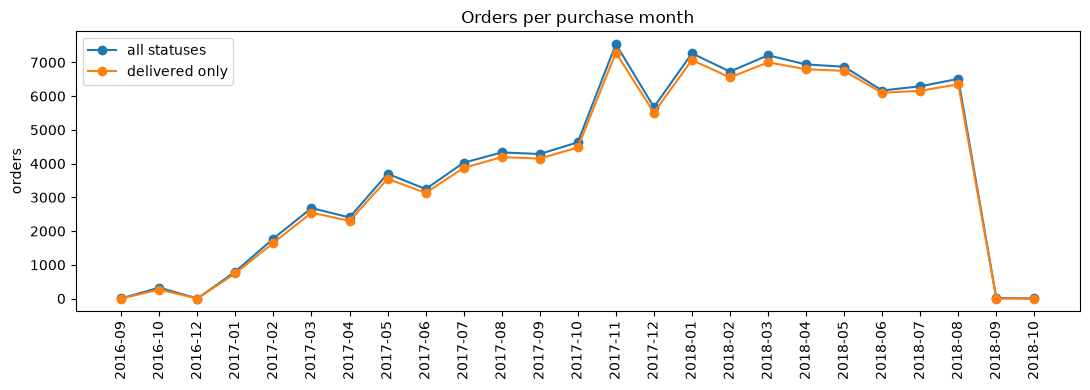

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
x = monthly.index.astype(str)
ax.plot(x, monthly["all_orders"], marker="o", label="all statuses")
ax.plot(x, monthly["delivered_orders"], marker="o", label="delivered only")
ax.set_title("Orders per purchase month")
ax.set_ylabel("orders")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Days with orders in each of the edge months: a month can look small because only a few days are covered.
days_with_orders = orders.groupby(purchase_month)["order_purchase_timestamp"].agg(
    first_purchase="min", last_purchase="max", n_orders="size"
)
days_with_orders["distinct_days"] = orders.groupby(purchase_month)["order_purchase_timestamp"].apply(
    lambda s: s.dt.date.nunique()
)
pd.concat([days_with_orders.head(5), days_with_orders.tail(4)])

,first_purchase,last_purchase,n_orders,distinct_days
order_purchase_timestamp,,,,
2016-09,2016-09-04 21:15:19,2016-09-15 12:16:38,4,4
2016-10,2016-10-02 22:07:52,2016-10-22 08:25:27,324,10
2016-12,2016-12-23 23:16:47,2016-12-23 23:16:47,1,1
2017-01,2017-01-05 11:56:06,2017-01-31 23:37:58,800,27
2017-02,2017-02-01 00:04:17,2017-02-28 23:47:08,1780,28
2018-07,2018-07-01 00:25:07,2018-07-31 23:54:20,6292,31
2018-08,2018-08-01 00:02:17,2018-08-31 16:13:44,6512,31
2018-09,2018-09-03 09:06:57,2018-09-29 09:13:03,16,11
2018-10,2018-10-01 15:30:09,2018-10-17 17:30:18,4,4


### 3b. Candidate window and the 180-day follow-up check

The window below is a **recommendation** chosen from the monthly table above (see the Finding). The cell checks
how much data it keeps and how many customers would have a full 180 days of follow-up inside it
(first delivered order on or before `WINDOW_END - 180 days`), which is what metric 5 in `docs/metrics.md` needs.

In [11]:
WINDOW_START = pd.Timestamp("2017-01-01")
WINDOW_END = pd.Timestamp("2018-08-31 23:59:59")  # inclusive end of the last trusted month

in_window = orders["order_purchase_timestamp"].between(WINDOW_START, WINDOW_END)
print(f"Orders in window:            {in_window.sum():,} of {len(orders):,} ({in_window.mean() * 100:.2f}%)")
print(f"Orders before window:        {(orders['order_purchase_timestamp'] < WINDOW_START).sum():,}")
print(f"Orders after window:         {(orders['order_purchase_timestamp'] > WINDOW_END).sum():,}")
in_window_delivered = delivered["order_purchase_timestamp"].between(WINDOW_START, WINDOW_END)
print(f"Delivered orders in window:  {in_window_delivered.sum():,} of {len(delivered):,}")

# First delivered order per real customer, inside the window.
win_cust = delivered_cust[delivered_cust["order_purchase_timestamp"].between(WINDOW_START, WINDOW_END)]
first_order = win_cust.groupby("customer_unique_id")["order_purchase_timestamp"].min()
FOLLOWUP_CUTOFF = WINDOW_END.normalize() - pd.Timedelta(days=180)
eligible = first_order <= FOLLOWUP_CUTOFF
print(f"\nCustomers whose first delivered order is in the window: {len(first_order):,}")
print(f"180-day follow-up cutoff (first order on or before):   {FOLLOWUP_CUTOFF.date()}")
print(f"... customers with full 180-day follow-up:             {eligible.sum():,} ({eligible.mean() * 100:.2f}%)")

Orders in window:            99,092 of 99,441 (99.65%)
Orders before window:        329
Orders after window:         20
Delivered orders in window:  96,211 of 96,478



Customers whose first delivered order is in the window: 93,104
180-day follow-up cutoff (first order on or before):   2018-03-04
... customers with full 180-day follow-up:             55,973 (60.12%)


**Finding (3 months)**

- Data runs from **2016-09-04 21:15:19** to **2018-10-17 17:30:18**.
- **Start is sparse:** 2016-09 has 4 orders on 4 days, 2016-10 has 324 orders on only 10 days, **2016-11 has no orders at all** (the month is missing from the table), and 2016-12 has a single order. 2017-01 is the first month with orders on most days (27 days, 800 orders) and volume grows steadily from there.
- **End is cut off:** 2018-08 is a full month (orders on 31 days, 6,512 orders, 97.5% delivered). Then 2018-09 has only 16 orders and 2018-10 only 4, with **0 delivered** in both. The last delivered order was purchased on 2018-08-29. This looks like the end of the data extract, not a real drop in demand.
- Delivered share is 92.9%–98.9% for every month from 2017-01 to 2018-08.
- **Recommended window (awaiting approval): purchases 2017-01-01 to 2018-08-31.** It keeps 99,092 of 99,441 orders (99.65%) and drops 329 orders before and 20 after. 96,211 of the 96,478 delivered orders are inside it.
- 180-day follow-up: of the 93,104 customers whose first delivered order is in the window, **55,973 (60.12%)** bought on or before 2018-03-04 and so have a full 180 days of follow-up before the window ends. These are the customers the repeat-within-180-days metric can fairly judge.

## 4. Date problems

**Question:** are the order timestamps consistent with the order's status and with each other?

Each check is a True/False test per order; summing it counts the orders that fail. A comparison involving a blank
date (`NaT`) is False, so blanks never count as "out of order" — they are counted separately as missing.

In [12]:
o = orders
is_delivered = o["order_status"] == "delivered"

date_checks = {
    "delivered: missing order_delivered_customer_date": (is_delivered & o["order_delivered_customer_date"].isna()),
    "delivered: missing order_approved_at": (is_delivered & o["order_approved_at"].isna()),
    "delivered: missing order_delivered_carrier_date": (is_delivered & o["order_delivered_carrier_date"].isna()),
    "not delivered but has order_delivered_customer_date": (~is_delivered & o["order_delivered_customer_date"].notna()),
    "customer delivery before purchase": (o["order_delivered_customer_date"] < o["order_purchase_timestamp"]),
    "carrier date before approval": (o["order_delivered_carrier_date"] < o["order_approved_at"]),
    "carrier date before purchase (extra)": (o["order_delivered_carrier_date"] < o["order_purchase_timestamp"]),
    "customer delivery before carrier date (extra)": (o["order_delivered_customer_date"] < o["order_delivered_carrier_date"]),
    "approval before purchase (extra)": (o["order_approved_at"] < o["order_purchase_timestamp"]),
}
date_issue_counts = pd.Series({k: int(v.sum()) for k, v in date_checks.items()}, name="orders")
date_issue_counts.to_frame()

,orders
delivered: missing order_delivered_customer_date,8
delivered: missing order_approved_at,14
delivered: missing order_delivered_carrier_date,2
not delivered but has order_delivered_customer_date,6
customer delivery before purchase,0
carrier date before approval,1359
carrier date before purchase (extra),166
customer delivery before carrier date (extra),23
approval before purchase (extra),0


In [13]:
# Which statuses have a customer delivery date without being 'delivered'?
print("Not delivered but has customer delivery date, by status:")
print(o.loc[date_checks["not delivered but has order_delivered_customer_date"], "order_status"].value_counts().to_string())

# How big are the 'carrier before approval' gaps? Small gaps suggest clock/recording noise, big ones real errors.
bad = date_checks["carrier date before approval"]
gap_hours = (o.loc[bad, "order_approved_at"] - o.loc[bad, "order_delivered_carrier_date"]).dt.total_seconds() / 3600
print("\nCarrier-before-approval gap (hours):")
print(gap_hours.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(2).to_string())
print("Statuses of these orders:")
print(o.loc[bad, "order_status"].value_counts().to_string())

# Delivered orders missing the customer date: what else do they have?
miss = date_checks["delivered: missing order_delivered_customer_date"]
print("\nDelivered orders missing customer date — other dates present?")
print(o.loc[miss, ORDER_DATES].notna().sum().to_string())

Not delivered but has customer delivery date, by status:
order_status
canceled    6

Carrier-before-approval gap (hours):
count    1359.00
mean       24.75
std       115.31
min         0.01
25%         1.42
50%        17.17
75%        25.96
90%        51.60
max      4109.26
Statuses of these orders:
order_status
delivered    1350
shipped         9

Delivered orders missing customer date — other dates present?
order_purchase_timestamp         8
order_approved_at                8
order_delivered_carrier_date     7
order_delivered_customer_date    0
order_estimated_delivery_date    8


**Finding (4 dates)**

- Delivered orders missing `order_delivered_customer_date`: **8**. All 8 have purchase, approval and estimated dates, and 7 have a carrier date.
- Delivered orders missing `order_approved_at`: **14**. Delivered orders missing `order_delivered_carrier_date`: **2**.
- Non-delivered orders that have a customer delivery date: **6**, all `canceled`.
- Customer delivery before purchase: **0**. Approval before purchase: **0**.
- Carrier date before approval: **1,359** orders (1,350 delivered, 9 shipped). The gap is usually small (median 17.17 hours, 25% under 1.42 hours) but reaches 4,109.26 hours. This looks like recording noise in the approval or carrier timestamps rather than impossible orders.
- Carrier date before purchase: **166**. Customer delivery before carrier date: **23**.
- None of these break the key retention/delivery metrics (purchase → customer delivery is never negative), but they make the *approval → carrier* step unreliable for those orders.

## 5. Reviews: duplicates and "one review per order"

**Questions:**
1. Are there repeated `review_id`s, and do they point to different orders?
2. How many orders have more than one review?
3. How do `review_creation_date` (when the survey was sent / review created) and `review_answer_timestamp`
   (when the customer answered) relate?
4. For orders with several reviews, do both date columns agree on which review is the latest?

In [14]:
# 1. Repeated review_ids
rid_dup_rows = reviews["review_id"].duplicated(keep=False)
n_dup_review_id_values = reviews.loc[rid_dup_rows, "review_id"].nunique()
orders_per_rid = reviews.groupby("review_id")["order_id"].nunique()
print(f"review_id values appearing more than once: {n_dup_review_id_values:,}")
print(f"rows involved:                             {rid_dup_rows.sum():,}")
print(f"review_ids linked to >1 different order:   {(orders_per_rid > 1).sum():,}")

# Are the repeated review_id rows identical apart from order_id?
other_cols = [c for c in reviews.columns if c not in ("order_id",)]
varying = reviews[rid_dup_rows].groupby("review_id")[other_cols].nunique(dropna=False).gt(1).sum()
print("\nAmong repeated review_ids, how many have differing values in each column:")
print(varying.to_string())

# 2. Orders with more than one review
reviews_per_order = reviews.groupby("order_id")["review_id"].nunique()
print("\nDistinct reviews per order:")
print(reviews_per_order.value_counts().sort_index().to_string())
n_orders_multi_review = int((reviews_per_order > 1).sum())
print(f"Orders with more than one review: {n_orders_multi_review:,}")

review_id values appearing more than once: 789
rows involved:                             1,603
review_ids linked to >1 different order:   789

Among repeated review_ids, how many have differing values in each column:
review_id                  0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0



Distinct reviews per order:
review_id
1    98126
2      543
3        4
Orders with more than one review: 547


In [15]:
# 3. How do the two dates relate?
answer_gap_days = (reviews["review_answer_timestamp"] - reviews["review_creation_date"]).dt.total_seconds() / 86400
print("Nulls  review_creation_date:", reviews["review_creation_date"].isna().sum(),
      "| review_answer_timestamp:", reviews["review_answer_timestamp"].isna().sum())
n_answer_before_creation = int((answer_gap_days < 0).sum())
print(f"Answer before creation: {n_answer_before_creation:,}")
creation_has_time = (reviews["review_creation_date"] != reviews["review_creation_date"].dt.normalize()).sum()
print(f"review_creation_date values with a time part other than 00:00:00: {creation_has_time:,}")
print("\nDays from creation to answer:")
print(answer_gap_days.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())

Nulls  review_creation_date: 0 | review_answer_timestamp: 0
Answer before creation: 0
review_creation_date values with a time part other than 00:00:00: 85

Days from creation to answer:
count    99224.00
mean         3.15
std          9.89
min          0.09
50%          1.67
90%          4.86
99%         22.07
max        518.70


In [16]:
# 4. Orders with several reviews: which review is 'latest' under each date column?
multi = reviews[reviews["order_id"].isin(reviews_per_order[reviews_per_order > 1].index)]

latest_by_creation = (
    multi.sort_values(["order_id", "review_creation_date", "review_answer_timestamp"])
    .groupby("order_id").tail(1).set_index("order_id")["review_id"]
)
latest_by_answer = (
    multi.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
    .groupby("order_id").tail(1).set_index("order_id")["review_id"]
)
agree = latest_by_creation == latest_by_answer.reindex(latest_by_creation.index)
print(f"Multi-review orders: {len(latest_by_creation):,}")
print(f"Both columns pick the same latest review: {agree.sum():,} ({agree.mean() * 100:.2f}%)")

# Ties: two reviews of the same order with the same creation date / same answer timestamp.
tie_creation = multi.duplicated(["order_id", "review_creation_date"], keep=False).groupby(multi["order_id"]).any()
tie_answer = multi.duplicated(["order_id", "review_answer_timestamp"], keep=False).groupby(multi["order_id"]).any()
print(f"Orders with a tie on review_creation_date:    {tie_creation.sum():,}")
print(f"Orders with a tie on review_answer_timestamp: {tie_answer.sum():,}")

# Do the multiple reviews of one order disagree on the score?
score_differs = multi.groupby("order_id")["review_score"].nunique().gt(1)
print(f"Multi-review orders whose scores differ: {score_differs.sum():,}")

Multi-review orders: 547
Both columns pick the same latest review: 501 (91.59%)
Orders with a tie on review_creation_date:    157
Orders with a tie on review_answer_timestamp: 0
Multi-review orders whose scores differ: 202


**Finding (5 reviews)**

- **789 review_ids appear more than once (1,603 rows).** Every one of them is linked to more than one *different* order, and the repeated rows are identical in score, comments and both dates. So one review was copied onto several orders. These are not junk rows: each (review_id, order_id) pair is a real link.
- Reviews per order: 98,126 orders have 1 review, 543 have 2, 4 have 3, so **547 orders have more than one review**. In 202 of them the scores differ, so which review we keep matters.
- Dates: neither column has nulls, and an answer never comes before creation (0 cases). The answer comes 1.67 days after creation at the median and 518.70 days at the maximum. `review_creation_date` is a date only (just 85 values carry a time of day), while `review_answer_timestamp` has full time.
- Within multi-review orders the two columns pick the same latest review in 501 of 547 orders (91.59%). But **157 orders tie on `review_creation_date`** and **0 tie on `review_answer_timestamp`**.
- **Recommendation (awaiting approval):** keep one review per order, the one with the latest `review_answer_timestamp`, using `review_creation_date` and then `review_id` only as tie-breakers. It is never null, has a time part, and produced no ties here. Keep the duplicated review_ids, because each one is a valid link to a different order.

## 6. Payments

**Questions:** how many payment rows per order, which payment types, any zero-value payments, any orders without
a payment, and does what the customer paid match the item lines (price + freight)?

Method for the comparison: aggregate **both** tables to one row per order first (sum of `payment_value`; sum of
`price + freight_value`), then compare. Joining item rows to payment rows directly would multiply rows and
double-count money. Differences are rounded to cents; a mismatch is a gap of more than R$0.01. Counts at R$1 are
shown to see how sensitive the result is to the tolerance.

In [17]:
payment_rows_per_order = payments.groupby("order_id").size()
print("Payment rows per order:")
print(payment_rows_per_order.value_counts().sort_index().to_string())

ptype = payments["payment_type"].value_counts().rename_axis("payment_type").reset_index(name="rows")
ptype["pct"] = (ptype["rows"] / len(payments) * 100).round(2)
print()
print(ptype.to_string(index=False))

zero_pay = payments["payment_value"] == 0
print(f"\nZero-value payment rows: {zero_pay.sum():,}")
print(payments.loc[zero_pay, "payment_type"].value_counts().to_string())
print(f"Rows with payment_installments = 0: {(payments['payment_installments'] == 0).sum():,}")

no_payment = ~orders["order_id"].isin(payments["order_id"])
print(f"\nOrders with no payment row: {no_payment.sum():,}")
print(orders.loc[no_payment, "order_status"].value_counts().to_string())

Payment rows per order:
1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1

payment_type  rows   pct
 credit_card 76795 73.92
      boleto 19784 19.04
     voucher  5775  5.56
  debit_card  1529  1.47
 not_defined     3  0.00

Zero-value payment rows: 9
payment_type
voucher        6
not_defined    3
Rows with payment_installments = 0: 2



Orders with no payment row: 1
order_status
delivered    1


In [18]:
paid_per_order = payments.groupby("order_id")["payment_value"].sum().rename("paid")
items_per_order_value = (
    items.assign(line_total=items["price"] + items["freight_value"])
    .groupby("order_id")["line_total"].sum().rename("items_total")
)
cmp = pd.concat([paid_per_order, items_per_order_value], axis=1, join="inner")
cmp["diff"] = (cmp["paid"] - cmp["items_total"]).round(2)

n_compared = len(cmp)
n_mismatch_001 = int((cmp["diff"].abs() > 0.01).sum())
n_mismatch_1 = int((cmp["diff"].abs() > 1).sum())
print(f"Orders with both payments and items: {n_compared:,}")
print(f"Mismatch > R$0.01: {n_mismatch_001:,} ({n_mismatch_001 / n_compared * 100:.2f}%)")
print(f"Mismatch > R$1.00: {n_mismatch_1:,} ({n_mismatch_1 / n_compared * 100:.2f}%)")
print(f"  paid more than items (> R$0.01): {(cmp['diff'] > 0.01).sum():,}")
print(f"  paid less than items (> R$0.01): {(cmp['diff'] < -0.01).sum():,}")
print("\nSize of the gap among mismatches > R$0.01 (R$):")
print(cmp.loc[cmp["diff"].abs() > 0.01, "diff"].describe(percentiles=[0.1, 0.5, 0.9]).round(2).to_string())

n_pay_no_items = int((~paid_per_order.index.isin(items_per_order_value.index)).sum())
print(f"\nOrders with payments but no items: {n_pay_no_items:,}")

Orders with both payments and items: 98,665
Mismatch > R$0.01: 303 (0.31%)
Mismatch > R$1.00: 249 (0.25%)
  paid more than items (> R$0.01): 264
  paid less than items (> R$0.01): 39

Size of the gap among mismatches > R$0.01 (R$):
count    303.00
mean       9.48
std       18.08
min      -51.62
10%       -0.02
50%        5.41
90%       24.91
max      182.81

Orders with payments but no items: 775


**Finding (6 payments)**

- Payment rows per order: 96,479 orders have 1 row, 2,382 have 2, and the maximum is 29 rows. This is why payments must be summed per order before joining.
- Payment types: credit_card 76,795 rows (73.92%), boleto 19,784 (19.04%), voucher 5,775 (5.56%), debit_card 1,529 (1.47%), **not_defined 3**.
- **Zero-value payment rows: 9** (6 voucher, 3 not_defined). Rows with `payment_installments = 0`: 2.
- **Orders with no payment row: 1** (status delivered).
- Paid vs item lines (both summed to order level first), over 98,665 orders that have both: **303 mismatch by more than R$0.01 (0.31%)** and 249 by more than R$1.00 (0.25%). In 264 the customer paid *more* than price + freight and in 39 *less*. The median gap among mismatches is R$5.41 and the range is −R$51.62 to +R$182.81. The cause isn't proven here; instalment interest or vouchers are possibilities to check later. This is one reason `payment_value` is not used as revenue (metric 3).
- 775 orders have payments but no items; these are the same 775 orders with no items in section 7.

## 7. Items per order

**Question:** how many item rows does an order usually have, and are there orders with no items at all?

In [19]:
items_per_order = items.groupby("order_id").size()
print("Item rows per order:")
print(items_per_order.value_counts().sort_index().to_string())
print()
print(items_per_order.describe().round(2).to_string())

no_items = ~orders["order_id"].isin(items["order_id"])
n_orders_no_items = int(no_items.sum())
print(f"\nOrders with no item rows: {n_orders_no_items:,}")
print(orders.loc[no_items, "order_status"].value_counts().to_string())

# Is order_item_id a simple 1..n counter inside each order?
max_vs_count = items.groupby("order_id")["order_item_id"].max() == items_per_order
print(f"\nOrders where max(order_item_id) == number of item rows: {max_vs_count.mean() * 100:.2f}%")

Item rows per order:
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1

count    98666.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         21.00

Orders with no item rows: 775
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1



Orders where max(order_item_id) == number of item rows: 100.00%


**Finding (7 items)**

- Item rows per order: 88,863 orders have 1 item, 7,516 have 2, 1,322 have 3, and the maximum is 21. The mean is 1.14 items per order.
- **775 orders have no item rows**: unavailable 603, canceled 164, created 5, invoiced 2, shipped 1. These are almost all orders that never went through.
- `order_item_id` is a 1…n counter inside every order (max equals row count in 100.00% of orders), so `order_id + order_item_id` is a reliable item key.

## 8. Geolocation

**Questions:** how many coordinate rows are there per zip prefix, how many exact duplicate rows, are any
coordinates outside Brazil, and do all customer/seller zip prefixes appear in this table?

Brazil's rough bounding box used here: latitude −34 to +5.5, longitude −74 to −34.

In [20]:
geo_rows_per_prefix = geo.groupby("geolocation_zip_code_prefix").size()
print(f"Distinct zip prefixes: {len(geo_rows_per_prefix):,}")
print("Rows per prefix:")
print(geo_rows_per_prefix.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())
print(f"Exact duplicate rows: {geo.duplicated().sum():,}")

outside = ~(geo["geolocation_lat"].between(-34, 5.5) & geo["geolocation_lng"].between(-74, -34))
n_geo_outside = int(outside.sum())
print(f"\nRows outside Brazil's bounding box: {n_geo_outside:,}")
print(f"Zip prefixes with at least one such row: {geo.loc[outside, 'geolocation_zip_code_prefix'].nunique():,}")
geo.loc[outside, ["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng", "geolocation_state"]].head(10)

Distinct zip prefixes: 19,015
Rows per prefix:
count    19015.0
mean        52.6
std         72.1
min          1.0
50%         29.0
90%        124.0
99%        353.0
max       1146.0


Exact duplicate rows: 261,831

Rows outside Brazil's bounding box: 42
Zip prefixes with at least one such row: 21


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_state
387565,18243,28.008978,-15.536867,SP
513631,28165,41.614052,-8.411675,RJ
513643,28155,-34.586422,-58.732101,RJ
513754,28155,42.439286,13.820214,RJ
514429,28333,38.381672,-6.328200,RJ
516682,28595,43.684961,-7.411080,RJ
538512,29654,29.409252,-98.484121,ES
538557,29654,21.657547,-101.466766,ES
585242,35179,25.995203,-98.078544,MG
585260,35179,25.995245,-98.078533,MG


In [21]:
geo_prefixes = set(geo["geolocation_zip_code_prefix"])
cust_missing_geo = ~customers["customer_zip_code_prefix"].isin(geo_prefixes)
seller_missing_geo = ~sellers["seller_zip_code_prefix"].isin(geo_prefixes)
n_cust_missing_geo = int(cust_missing_geo.sum())
n_seller_missing_geo = int(seller_missing_geo.sum())
print(f"Customer rows whose zip prefix is not in geolocation: {n_cust_missing_geo:,} "
      f"({customers.loc[cust_missing_geo, 'customer_zip_code_prefix'].nunique():,} distinct prefixes)")
print(f"Seller rows whose zip prefix is not in geolocation:   {n_seller_missing_geo:,} "
      f"({sellers.loc[seller_missing_geo, 'seller_zip_code_prefix'].nunique():,} distinct prefixes)")

# Is the prefix always 5 characters (leading zeros kept)?
for name, s in [("customers", customers["customer_zip_code_prefix"]),
                ("sellers", sellers["seller_zip_code_prefix"]),
                ("geolocation", geo["geolocation_zip_code_prefix"])]:
    print(f"{name}: zip prefix lengths -> {s.str.len().value_counts().to_dict()}")

Customer rows whose zip prefix is not in geolocation: 278 (157 distinct prefixes)
Seller rows whose zip prefix is not in geolocation:   7 (7 distinct prefixes)
customers: zip prefix lengths -> {5: 99441}
sellers: zip prefix lengths -> {5: 3095}
geolocation: zip prefix lengths -> {5: 1000163}


**Finding (8 geolocation)**

- 19,015 distinct zip prefixes. Rows per prefix: median 29, 99th percentile 353, maximum 1,146. So geolocation is *many coordinate points per prefix*, not one row per prefix.
- **261,831 rows are exact duplicates.**
- **42 rows (in 21 prefixes) fall outside Brazil's rough bounding box.** The examples show coordinates in Europe and North America for Brazilian states (SP, RJ, ES, MG), which points to bad geocoding.
- **278 customer rows (157 prefixes) and 7 seller rows (7 prefixes) have a zip prefix that is not in geolocation**, so a join on zip would leave them without coordinates.
- All zip prefixes are 5 characters in all three tables, so leading zeros were preserved by reading them as text.

## 9. Products and category translation

**Questions:** how many products have no category, which categories have no English translation, and which other
product attributes are missing (and is it the same products)?

Note: the raw column names really are misspelled (`product_name_lenght`, `product_description_lenght`).

In [22]:
n_missing_category = int(products["product_category_name"].isna().sum())
print(f"Products with no category: {n_missing_category:,} of {len(products):,}")

untranslated = sorted(set(products["product_category_name"].dropna()) - set(translation["product_category_name"]))
n_untranslated_categories = len(untranslated)
print(f"Categories with no English translation: {n_untranslated_categories}")
for c in untranslated:
    print(f"  {c}: {(products['product_category_name'] == c).sum()} products")

unused_translations = sorted(set(translation["product_category_name"]) - set(products["product_category_name"].dropna()))
print(f"Translation rows not used by any product: {len(unused_translations)} {unused_translations}")

Products with no category: 610 of 32,951
Categories with no English translation: 2
  pc_gamer: 3 products
  portateis_cozinha_e_preparadores_de_alimentos: 10 products
Translation rows not used by any product: 0 []


In [23]:
attr_cols = [c for c in products.columns if c != "product_id"]
print("Missing values per product attribute:")
print(products[attr_cols].isna().sum().to_string())

text_cols = ["product_category_name", "product_name_lenght", "product_description_lenght", "product_photos_qty"]
size_cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
print(f"\nProducts missing ALL four text attributes together: {products[text_cols].isna().all(axis=1).sum():,}")
print(f"Products missing ANY text attribute:                {products[text_cols].isna().any(axis=1).sum():,}")
print(f"Products missing ALL size attributes together:      {products[size_cols].isna().all(axis=1).sum():,}")
print(f"Products missing ANY size attribute:                {products[size_cols].isna().any(axis=1).sum():,}")
print(f"Products with weight = 0 g:                         {(products['product_weight_g'] == 0).sum():,}")

items_no_category = items["product_id"].isin(products.loc[products["product_category_name"].isna(), "product_id"])
n_items_no_category = int(items_no_category.sum())
print(f"\nItem rows whose product has no category: {n_items_no_category:,} ({items_no_category.mean() * 100:.2f}% of items)")

Missing values per product attribute:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

Products missing ALL four text attributes together: 610
Products missing ANY text attribute:                610
Products missing ALL size attributes together:      2
Products missing ANY size attribute:                2
Products with weight = 0 g:                         4

Item rows whose product has no category: 1,603 (1.42% of items)


**Finding (9 products)**

- **610 products (of 32,951) have no category.** They are the *same* 610 products that lack name length, description length and photo count (missing ALL four = missing ANY = 610).
- **2 categories have no English translation:** `pc_gamer` (3 products) and `portateis_cozinha_e_preparadores_de_alimentos` (10 products). Every translation row is used by at least one product.
- 2 products lack all four size attributes (weight, length, height, width), and 4 products have weight = 0 g.
- 1,603 item rows (1.42% of items) belong to products with no category, so category-level analysis would put them in an "unknown" bucket.

## 10. Price and freight distributions

**Question:** what do item prices and freight values look like, what is in the top 1%, and how many items have
zero freight? Outliers are **flagged only** — nothing is removed in this step.

In [24]:
print(items[["price", "freight_value"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())

p99_price = items["price"].quantile(0.99)
p99_freight = items["freight_value"].quantile(0.99)
n_price_above_p99 = int((items["price"] > p99_price).sum())
n_freight_above_p99 = int((items["freight_value"] > p99_freight).sum())
n_zero_freight = int((items["freight_value"] == 0).sum())
n_zero_price = int((items["price"] <= 0).sum())
n_freight_gt_price = int((items["freight_value"] > items["price"]).sum())
print(f"\n99th percentile price:   R${p99_price:,.2f}  -> items above: {n_price_above_p99:,}")
print(f"99th percentile freight: R${p99_freight:,.2f}  -> items above: {n_freight_above_p99:,}")
print(f"Items with zero freight:          {n_zero_freight:,}")
print(f"Items with price <= 0:            {n_zero_price:,}")
print(f"Items where freight > price:      {n_freight_gt_price:,}")

print("\nFive most expensive item rows:")
print(items.nlargest(5, "price")[["order_id", "product_id", "price", "freight_value"]].to_string(index=False))
print("\nFive highest-freight item rows:")
print(items.nlargest(5, "freight_value")[["order_id", "product_id", "price", "freight_value"]].to_string(index=False))

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
90%       229.80          34.04
99%       890.00          84.52
max      6735.00         409.68

99th percentile price:   R$890.00  -> items above: 1,117
99th percentile freight: R$84.52  -> items above: 1,124
Items with zero freight:          383
Items with price <= 0:            0
Items where freight > price:      4,124

Five most expensive item rows:
                        order_id                       product_id  price  freight_value
0812eb902a67711a1cb742b3cdaa65ae 489ae2aa008f021502940f251d4cce7f 6735.0         194.31
fefacc66af859508bf1a7934eab1e97f 69c590f7ffc7bf8db97190b6cb6ed62e 6729.0         193.21
f5136e38d1a14a4dbd87dff67da82701 1bdf5e6731585cf01aa8169c7028d6ad 6499.0         227.66
a96610ab360d42a2e5335a3998b4718a a64

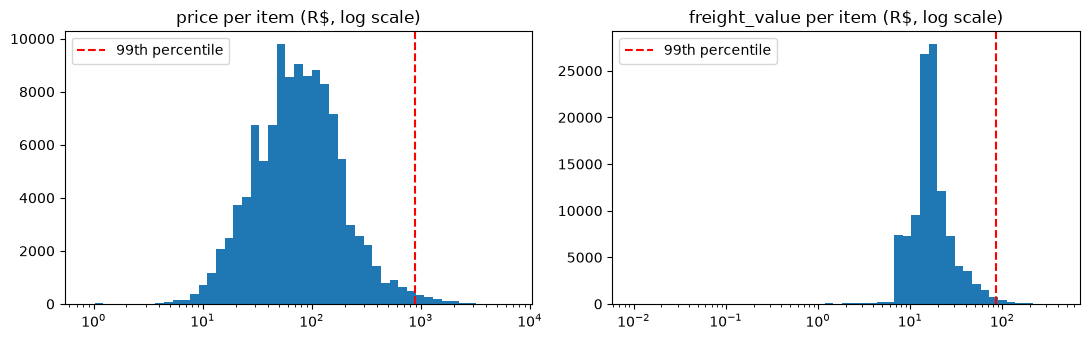

In [25]:
# Log-scale histograms: prices are heavily right-skewed, so a normal axis squashes almost everything into one bar.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["price", "freight_value"]):
    vals = items.loc[items[col] > 0, col]  # log scale cannot show zeros; zero freight is counted above
    ax.hist(vals, bins=np.logspace(np.log10(vals.min()), np.log10(vals.max()), 50))
    ax.set_xscale("log")
    ax.axvline(items[col].quantile(0.99), color="red", linestyle="--", label="99th percentile")
    ax.set_title(f"{col} per item (R$, log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

**Finding (10 price freight)**

- Price per item: median R$74.99, mean R$120.65, 99th percentile R$890.00, max R$6,735.00. The minimum is R$0.85 and no price is zero or negative. The data is strongly right-skewed (mean well above median).
- Freight per item: median R$16.26, 99th percentile R$84.52, max R$409.68.
- **1,117 items are priced above the 99th percentile and 1,124 have freight above it.** The top rows look like genuinely expensive goods with matching high freight, not typos. **Flagged only, nothing removed.**
- **383 items have zero freight** (free shipping is plausible). 4,124 items have freight higher than their price.

## 11. Referential integrity

**Question:** does every foreign key point at a row that exists? `isin` checks each value against the set of valid
keys; `~` flips it, so we count the values that are **not** found.

In [26]:
order_ids = set(orders["order_id"])
ri = {
    "orders whose customer_id is not in customers": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "items whose product_id is not in products": (~items["product_id"].isin(products["product_id"])).sum(),
    "items whose seller_id is not in sellers": (~items["seller_id"].isin(sellers["seller_id"])).sum(),
    "items whose order_id is not in orders": (~items["order_id"].isin(order_ids)).sum(),
    "payments whose order_id is not in orders": (~payments["order_id"].isin(order_ids)).sum(),
    "reviews whose order_id is not in orders": (~reviews["order_id"].isin(order_ids)).sum(),
    "customers with no order (extra)": (~customers["customer_id"].isin(orders["customer_id"])).sum(),
    "orders with no review (extra)": (~orders["order_id"].isin(reviews["order_id"])).sum(),
    "products never sold (extra)": (~products["product_id"].isin(items["product_id"])).sum(),
    "sellers with no items (extra)": (~sellers["seller_id"].isin(items["seller_id"])).sum(),
}
ri_counts = pd.Series({k: int(v) for k, v in ri.items()}, name="rows")
ri_counts.to_frame()

,rows
orders whose customer_id is not in customers,0
items whose product_id is not in products,0
items whose seller_id is not in sellers,0
items whose order_id is not in orders,0
payments whose order_id is not in orders,0
reviews whose order_id is not in orders,0
customers with no order (extra),0
orders with no review (extra),768
products never sold (extra),0
sellers with no items (extra),0


**Finding (11 integrity)**

- All foreign keys resolve: 0 orders with an unknown customer_id, 0 items with an unknown product_id or seller_id, and 0 items, payments or reviews with an order_id that is not in orders.
- Every customer row has an order, every product was sold at least once, and every seller has items.
- **768 orders have no review at all**, which matters for review analysis coverage.
- Referential integrity is clean, so no rows need to be dropped for orphan keys.

## 12. Key numbers

One tidy table of the headline figures and every issue count found above. It is saved to
`outputs/phase2_profile_summary.csv` so later phases (and the README) can cite it.

In [27]:
summary_rows = [
    ("total_orders", len(orders)),
    ("delivered_orders", len(delivered)),
    ("delivered_orders_pct", round(len(delivered) / len(orders) * 100, 2)),
    ("unique_customer_id", n_customer_id),
    ("unique_customer_unique_id", n_customer_unique_id),
    ("customers_with_delivered_order", n_customers_with_delivered),
    ("one_time_customers_delivered", n_one_time),
    ("one_time_customers_delivered_pct", round(pct_one_time, 2)),
    ("first_purchase_timestamp", str(orders["order_purchase_timestamp"].min())),
    ("last_purchase_timestamp", str(orders["order_purchase_timestamp"].max())),
    ("recommended_window_start", str(WINDOW_START.date())),
    ("recommended_window_end", str(WINDOW_END.date())),
    ("orders_in_recommended_window", int(in_window.sum())),
    ("customers_with_180d_followup_in_window", int(eligible.sum())),
    # Section 0
    ("fully_duplicated_rows_geolocation", int(geo.duplicated().sum())),
    ("fully_duplicated_rows_other_tables", int(sum(df.duplicated().sum() for n, df in tables.items() if n != "geolocation"))),
    ("reviews_rows_repeating_review_id", int(reviews["review_id"].duplicated().sum())),
    ("reviews_rows_repeating_order_id", int(reviews["order_id"].duplicated().sum())),
    # Section 2
    *[(f"orders_status_{s}", int(n)) for s, n in orders["order_status"].value_counts().items()],
    # Section 4
    *[("date_issue: " + k, int(v)) for k, v in date_issue_counts.items()],
    # Section 5
    ("review_id_values_repeated", n_dup_review_id_values),
    ("orders_with_more_than_one_review", n_orders_multi_review),
    ("reviews_answer_before_creation", n_answer_before_creation),
    # Section 6
    ("orders_with_no_payment", int(no_payment.sum())),
    ("zero_value_payment_rows", int(zero_pay.sum())),
    ("payment_type_not_defined_rows", int((payments["payment_type"] == "not_defined").sum())),
    ("orders_payment_vs_items_mismatch_gt_0_01", n_mismatch_001),
    ("orders_payment_vs_items_mismatch_gt_1_00", n_mismatch_1),
    # Section 7
    ("orders_with_no_items", n_orders_no_items),
    # Section 8
    ("geolocation_distinct_zip_prefixes", len(geo_rows_per_prefix)),
    ("geolocation_rows_outside_brazil_box", n_geo_outside),
    ("customer_rows_zip_not_in_geolocation", n_cust_missing_geo),
    ("seller_rows_zip_not_in_geolocation", n_seller_missing_geo),
    # Section 9
    ("products_missing_category", n_missing_category),
    ("categories_missing_translation", n_untranslated_categories),
    ("items_with_product_missing_category", n_items_no_category),
    # Section 10
    ("items_price_above_p99", n_price_above_p99),
    ("items_freight_above_p99", n_freight_above_p99),
    ("items_zero_freight", n_zero_freight),
    # Section 11
    *[("integrity: " + k, int(v)) for k, v in ri_counts.items()],
]
key_numbers = pd.DataFrame(summary_rows, columns=["metric", "value"])
key_numbers.to_csv(OUT / "phase2_profile_summary.csv", index=False)
print(f"Saved {len(key_numbers)} rows to {OUT / 'phase2_profile_summary.csv'}")
key_numbers

Saved 64 rows to D:\Projects\olist-retention-analysis\outputs\phase2_profile_summary.csv


,metric,value
0,total_orders,99441
1,delivered_orders,96478
2,delivered_orders_pct,97.02
3,unique_customer_id,99441
4,unique_customer_unique_id,96096
5,customers_with_delivered_order,93358
6,one_time_customers_delivered,90557
7,one_time_customers_delivered_pct,97.0
8,first_purchase_timestamp,2016-09-04 21:15:19
9,last_purchase_timestamp,2018-10-17 17:30:18


**Finding (12 key numbers)**

The table above is saved to `outputs/phase2_profile_summary.csv` (64 rows). Every value is produced by the cells of this notebook; the window start and end are the *recommended* window from section 3b, not yet approved.